# Dataset B: H1N1 Vaccine Acceptance and Cost Analysis

## Research objective
Predict individual H1N1 vaccine acceptance and evaluate prediction-based
vaccine allocation using the town's expected vaccine, compensation,
and hospitalisation costs.

## Initial data inspection
We first load the labelled training data and the unlabelled test data.
We check their dimensions, column names, and example records before
making preprocessing or modelling decisions.

The respondent_id column identifies respondents and will be preserved
for submission alignment, but excluded from model predictors.

In [ ]:
from pathlib import Path

import pandas as pd
from google.colab import files
from IPython.display import display

# File names supplied for Dataset B.
train_path = Path("/content/dataset_B_training.csv")
test_path = Path("/content/dataset_B_testing.csv")

# Upload the datasets only if either required file is missing.
if not train_path.exists() or not test_path.exists():
    print("Upload dataset_B_training.csv and dataset_B_testing.csv.")
    files.upload()

# Check that the expected files are available.
missing_files = [
    path.name
    for path in [train_path, test_path]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Required files not found: {missing_files}"
    )

# Keep the original datasets unchanged.
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training dimensions:", train_df.shape)
print("Testing dimensions:", test_df.shape)

print("\nTraining column names:")
print(train_df.columns.tolist())

print("\nColumns present only in training:")
print(sorted(set(train_df.columns) - set(test_df.columns)))

print("\nColumns present only in testing:")
print(sorted(set(test_df.columns) - set(train_df.columns)))

print("\nFirst five training rows:")
display(train_df.head())

print("\nFirst five testing rows:")
display(test_df.head())

Training dimensions: (4756, 31)
Testing dimensions: (4749, 30)

Training column names:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions', 'h1n1_vaccine']

Columns present only in training:
['h1n1_vaccine']

Columns present only in testing:
[]

First five training rows:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0



First five testing rows:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Female,"<= $75,000, Above Poverty",Not Married,Own,Not in Labor Force,"MSA, Principle City",0.0,0.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,Female,NaN,NaN,NaN,NaN,"MSA, Not Principle City",0.0,0.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Male,NaN,Married,Own,Not in Labor Force,"MSA, Principle City",1.0,0.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,1.0,0.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,Non-MSA,0.0,0.0,wholesale,0


## Results: Initial data loading

Training contains 4,756 respondents and 31 columns. Testing contains
4,749 respondents and 30 columns. The only column unique to training is
`h1n1_vaccine`, so every predictor in the test set is present in
training. The displayed rows show plausible values but also missing
entries, particularly in `income_poverty`, `rent_or_own`, and
`employment_sector`.

### Interpretation
- The datasets are structurally compatible for prediction, so we can use
  the same features during training and testing.
- Missing values are meaningful rather than accidental: `employment_sector`
  is unavailable for people who are not employed, and this context should
  guide our preprocessing choices.
- The target exists only in training, so we must split training data into
  development and audit subsets before comparing models.

In [ ]:
print("Training respondent_id summary")
print(train_df["respondent_id"].describe())
print()
print("Unique training IDs:", train_df["respondent_id"].nunique())
print("Unique testing IDs:", test_df["respondent_id"].nunique())
print("Training/test ID overlap:",
      len(set(train_df["respondent_id"]) & set(test_df["respondent_id"])))
print("Training duplicate feature rows:",
      train_df.duplicated(subset=[c for c in train_df.columns if c not in ["respondent_id", "h1n1_vaccine"]]).sum())
print("Testing duplicate feature rows:",
      test_df.duplicated(subset=[c for c in test_df.columns if c != "respondent_id"]).sum())
print()
print("Training target distribution:")
print(train_df["h1n1_vaccine"].value_counts(dropna=False))
print()
print("Training target proportion:",
      train_df["h1n1_vaccine"].mean())

Training respondent_id summary
count    4756.00000
mean     2378.50000
std      1373.08327
min         1.00000
25%      1189.75000
50%      2378.50000
75%      3567.25000
max      4756.00000
Name: respondent_id, dtype: float64

Unique training IDs: 4756
Unique testing IDs: 4749
Training/test ID overlap: 0
Training duplicate feature rows: 0
Testing duplicate feature rows: 2

Training target distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Training target proportion: 0.3940285954583684


## Results: Data integrity and target distribution

Training and testing have unique identifiers, and none overlap between
the datasets. Training has no duplicate feature profiles, but the test
set has two duplicate feature profiles. The target contains no missing
values: 2,882 respondents declined the vaccine and 1,874 accepted it.
The observed acceptance prevalence is 0.394.

### Interpretation
- The data are internally consistent and can support predictive
  modelling without needing duplicate removal.
- The target classes are moderately imbalanced, so threshold-based
  performance can depend heavily on the probability cut-off.
- The training set is large enough for cross-validated modelling and a
  reserved audit subset.
- The duplicate test profiles may identify distinct respondents or
  record errors. We should inspect them before treating them as
  independent examples, while ensuring every required respondent_id is
  retained for submission.

In [ ]:
duplicate_columns = [
    column for column in test_df.columns if column != "respondent_id"
]

duplicate_testing_profiles = (
    test_df[test_df.duplicated(subset=duplicate_columns, keep=False)]
    .sort_values(by=duplicate_columns)
    .copy()
)

print("Testing rows sharing a complete feature profile:")
display(duplicate_testing_profiles)

feature_columns = [
    column for column in train_df.columns
    if column not in ["respondent_id", "h1n1_vaccine"]
]

train_profile_matches = (
    train_df[feature_columns]
    .apply(tuple, axis=1)
    .isin(test_df[feature_columns].apply(tuple, axis=1))
)

print("Training rows matching a complete test feature profile:",
      train_profile_matches.sum())

Testing rows sharing a complete feature profile:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
1496,6253,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Married,Own,Employed,"MSA, Not Principle City",1.0,0.0,science,0
2411,7168,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Married,Own,Employed,"MSA, Not Principle City",1.0,0.0,science,0
1733,6490,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,healthcare,0
2554,7311,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,healthcare,0


Training rows matching a complete test feature profile: 2


## Results: Duplicate test profiles

Two pairs of test respondents share every predictor value but have
different respondent IDs. Two training respondents have the same
feature profile as two of these test respondents. No duplicate training
feature profiles were found.

### Interpretation
- Identical predictor profiles in the test set may identify genuine
  duplicates, separate respondents with matching circumstances, or a
  coding issue in respondent_id.
- The exact matches with training suggest a one-time data split rather
  than completely independent populations.
- Because respondent_id is required for scoring, we must keep all four
  test rows and assign predictions to each of their IDs.
- The two matching training profiles can be examined to see whether their
  outcomes are useful, but they do not by themselves prove that the
  duplicate test records represent the same individuals.

In [ ]:
train_feature_profiles = (
    train_df[feature_columns].apply(tuple, axis=1)
)
test_feature_profiles = (
    test_df[feature_columns].apply(tuple, axis=1)
)

matched_training_ids = (
    train_df.loc[
        train_feature_profiles.isin(test_feature_profiles),
        "respondent_id",
    ]
    .tolist()
)

print("Training IDs matching test feature profiles:",
      matched_training_ids)

for respondent in matched_training_ids:
    match = train_df[train_df["respondent_id"] == respondent].iloc[0]
    print("\nTraining respondent", respondent)
    print("h1n1_vaccine:", int(match["h1n1_vaccine"]))
    print("age_group:", match["age_group"])
    print("number_chronic_med_conditions:",
          match["number_chronic_med_conditions"])

Training IDs matching test feature profiles: [426, 781]

Training respondent 426
h1n1_vaccine: 0
age_group: 55 - 64 Years
number_chronic_med_conditions: 0

Training respondent 781
h1n1_vaccine: 0
age_group: 65+ Years
number_chronic_med_conditions: 0


## Results: Matching training and test profiles

The two training respondents whose complete predictor profiles match
test respondents (IDs 426 and 781) both declined the H1N1 vaccine.
Both are older adults with no recorded chronic medical conditions.

### Interpretation
- The matching training outcomes provide contextual evidence but are
  insufficient to determine predictions for the corresponding test
  respondents.
- Matching profiles do not establish that these are the same
  individuals, especially because they contain no birth date or unique
  personal identifier.
- We should retain all required test respondent IDs and let the
  fitted models determine their predicted acceptance probabilities.
- This finding will be revisited as a diagnostic observation after the
  models are trained, rather than being used as a hard-coded rule.

**target-independent quality checks**

In [ ]:
missing_summary = (
    pd.DataFrame({
        "training_missing_count": train_df[feature_columns].isna().sum(),
        "training_missing_percent": (
            train_df[feature_columns].isna().mean() * 100
        ),
        "testing_missing_count": test_df[feature_columns].isna().sum(),
        "testing_missing_percent": (
            test_df[feature_columns].isna().mean() * 100
        ),
    })
    .sort_values("training_missing_percent", ascending=False)
)

print("Missing values in predictors:")
display(missing_summary)

print("\nPredictor dtypes:")
display(train_df[feature_columns].dtypes.value_counts())

print("\nPredictors with unique values:")
display(train_df[feature_columns].nunique().sort_values(ascending=False))

Missing values in predictors:


,training_missing_count,training_missing_percent,testing_missing_count,testing_missing_percent
employment_sector,2364,49.705635,2405,50.642240
health_insurance,1925,40.475189,1982,41.735102
income_poverty,712,14.970563,797,16.782481
doctor_recc_h1n1,319,6.707317,345,7.264687
rent_or_own,315,6.623213,379,7.980628
employment_status,235,4.941127,277,5.832807
marital_status,226,4.751892,269,5.664350
education,224,4.709840,269,5.664350
child_under_6_months,134,2.817494,155,3.263845
health_worker,131,2.754415,149,3.137503



Predictor dtypes:


,count
float64,18
object,10
int64,1



Predictors with unique values:


,0
employment_sector,21
number_chronic_med_conditions,7
opinion_h1n1_vacc_effective,5
opinion_h1n1_risk,5
opinion_h1n1_sick_from_vacc,5
age_group,5
education,4
race,4
h1n1_concern,4
household_children,4


## Results: Missingness and feature structure

Two predictors have very high missingness:
- `employment_sector`: 49.7% missing in training and 50.6% missing in
  testing.
- `health_insurance`: 40.5% missing in training and 41.7% missing in
  testing.

Other predictors have much lower missingness, while five variables are
fully complete: `age_group`, `sex`, `race`, `census_msa`, and
`number_chronic_med_conditions`. Predictors contain 18 float variables,
10 text variables, and 1 integer variable. The maximum number of unique
predictor values is 21 for `employment_sector`.

### Interpretation
- Missingness is patterned rather than random, likely connected to
  employment and survey coverage. It should be encoded as an explicit
  category rather than being imputed as a typical value.
- Dropping these predictors or rows could remove almost half the sample,
  reducing the model's ability to represent people without recorded
  employment or insurance information.
- Numeric and text predictors require different preprocessing. Missing
  categorical indicators can be encoded as an explicit "not recorded"
  category, while numeric predictors can be compared under explicit
  imputation strategies.
- `number_chronic_med_conditions` has seven values, including zero, so it
  should be treated as an ordinal count rather than an arbitrary label.
- We will preserve all required respondent IDs and compare preprocessing
  choices without using the target to tune missing-value handling.

**explain missingness categories**

In [ ]:
for predictor in [
    "employment_sector",
    "health_insurance",
    "income_poverty",
    "doctor_recc_h1n1",
    "rent_or_own",
    "employment_status",
]:
    print("\nPredictor:", predictor)
    print("Training missing rows:")
    display(
        train_df[train_df[predictor].isna()]
        .groupby([
            "employment_status",
            "age_group",
        ])
        .size()
        .sort_values(ascending=False)
        .head()
    )


Predictor: employment_sector
Training missing rows:


employment_status   age_group    
Not in Labor Force  65+ Years        981
                    55 - 64 Years    361
                    18 - 34 Years    241
                    45 - 54 Years    142
                    35 - 44 Years    113
dtype: int64


Predictor: health_insurance
Training missing rows:


employment_status   age_group    
Not in Labor Force  65+ Years        337
Employed            45 - 54 Years    275
                    55 - 64 Years    222
                    18 - 34 Years    209
                    35 - 44 Years    189
dtype: int64


Predictor: income_poverty
Training missing rows:


employment_status   age_group    
Not in Labor Force  65+ Years        198
Employed            55 - 64 Years     51
                    45 - 54 Years     43
                    18 - 34 Years     39
Not in Labor Force  55 - 64 Years     37
dtype: int64

... (2 outputs left out)


Predictor: rent_or_own
Training missing rows:


employment_status   age_group    
Not in Labor Force  65+ Years        28
Employed            45 - 54 Years    14
                    55 - 64 Years    12
Not in Labor Force  18 - 34 Years     9
Employed            35 - 44 Years     9
dtype: int64


Predictor: employment_status
Training missing rows:


,,0
employment_status,age_group,


## Results: Missingness relationships

Most missing `employment_sector` values occur among people outside the
labour force, especially those aged 65+. Missing `health_insurance` and
`income_poverty` also cluster among older respondents, but this pattern
is less tightly connected to employment status. `employment_status` itself
has no missing values.

### Interpretation
- The missing `employment_sector` values are largely explainable, because
  employment sector does not apply to people who are not employed.
- `employment_status` is therefore an important predictor and should be
  retained, rather than being used as a reason to discard employment data.
- Explicit missing-value categories can preserve the distinction between
  inapplicable employment sector and unanswered survey questions.
- The prevalence of missing records among older respondents means the
  model must rely on a suitable missingness category, rather than on
  imputation that might misrepresent their hospitalisation risk.
- Because `doctor_recc_h1n1` may be relevant to both acceptance and
  clinical risk, we should examine how its missingness relates to the
  target before assigning a missingness category.

**Target-Aware Missingness Diagnostics**

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split

random_state = 42

audit_df, development_df = train_test_split(
    train_df,
    test_size=0.8,
    stratify=train_df["h1n1_vaccine"],
    random_state=random_state,
)

print("Development target prevalence:",
      development_df["h1n1_vaccine"].mean())
print("Reserved audit target prevalence:",
      audit_df["h1n1_vaccine"].mean())

missing_target_summary = (
    development_df.assign(
        missing_health_insurance=development_df[
            "health_insurance"
        ].isna(),
        missing_income_poverty=development_df[
            "income_poverty"
        ].isna(),
        missing_doctor_recc_h1n1=development_df[
            "doctor_recc_h1n1"
        ].isna(),
        missing_employment_sector=development_df[
            "employment_sector"
        ].isna(),
    )
    .groupby("h1n1_vaccine")[
        [
            "missing_health_insurance",
            "missing_income_poverty",
            "missing_doctor_recc_h1n1",
            "missing_employment_sector",
        ]
    ]
    .mean()
)

print("\nMissingness proportion by target (development data):")
display(missing_target_summary)

Development target prevalence: 0.3939553219448095
Reserved audit target prevalence: 0.3943217665615142

Missingness proportion by target (development data):


,missing_health_insurance,missing_income_poverty,missing_doctor_recc_h1n1,missing_employment_sector
h1n1_vaccine,,,,
0,0.511709,0.152645,0.086297,0.498265
1,0.239493,0.135424,0.031354,0.472982


## Results: Split validation and target-related missingness

The stratified split retains almost identical target prevalence in the
development and reserved audit sets, both close to the original 39.4%.
Within the development set, missingness differs by target outcome:
- `health_insurance`: 51.2% missing among refusers versus 23.9% among
  acceptors.
- `doctor_recc_h1n1`: 8.6% missing among refusers versus 3.1% among
  acceptors.
- `income_poverty`: 15.3% missing among refusers versus 13.5% among
  acceptors.
- `employment_sector`: 49.8% missing among refusers versus 47.3% among
  acceptors.

### Interpretation
- Missingness is informative, so treating "not recorded" as a distinct
  category is preferable to imputing a typical value.
- The stronger relationship between missing health-insurance records and
  vaccine refusal suggests that missingness may carry information related
  to survey or access barriers, rather than being random.
- The similar employment-sector missingness by target supports our
  interpretation that much of it reflects being outside the labour force.
- The reserved audit set remains untouched. This ensures the final
  comparison will estimate performance on data not used for exploratory
  decisions or model selection.

In [ ]:
categorical_predictors = [
    "age_group",
    "education",
    "race",
    "sex",
    "income_poverty",
    "marital_status",
    "rent_or_own",
    "employment_status",
    "census_msa",
]

target_by_category = {}

for predictor in categorical_predictors:
    category_summary = (
        development_df.groupby(
            predictor,
            dropna=False,
        )["h1n1_vaccine"]
        .agg(
            acceptors="sum",
            total="count",
            acceptance_rate="mean",
        )
        .sort_values("acceptance_rate", ascending=False)
    )
    target_by_category[predictor] = category_summary
    print("\nPredictor:", predictor)
    display(category_summary)


Predictor: age_group


,acceptors,total,acceptance_rate
age_group,,,
55 - 64 Years,350,841,0.416171
65+ Years,405,979,0.413687
35 - 44 Years,212,522,0.406130
45 - 54 Years,273,739,0.369418
18 - 34 Years,259,724,0.357735



Predictor: education


,acceptors,total,acceptance_rate
education,,,
College Graduate,662,1491,0.443997
Some College,414,1000,0.414000
NaN,58,176,0.329545
12 Years,267,823,0.324423
< 12 Years,98,315,0.311111



Predictor: race


,acceptors,total,acceptance_rate
race,,,
Hispanic,95,233,0.407725
White,1248,3087,0.404276
Other or Multiple,90,234,0.384615
Black,66,251,0.262948


... (8 outputs left out)


Predictor: employment_status


,acceptors,total,acceptance_rate
employment_status,,,
Employed,793,1962,0.404179
Not in Labor Force,586,1455,0.402749
NaN,67,189,0.354497
Unemployed,53,199,0.266332



Predictor: census_msa


,acceptors,total,acceptance_rate
census_msa,,,
Non-MSA,403,1009,0.399405
"MSA, Not Principle City",671,1696,0.395637
"MSA, Principle City",425,1100,0.386364


## Results: Categorical predictors and acceptance

Acceptance rates are higher among:
- Higher-income respondents: 44.3% above \$75,000, versus about 35.8%
  below poverty.
- College graduates: 44.4%, versus 31.1% for less than 12 years of
  education.
- Married respondents: 42.8%, versus 35.6% for those not married.
- Respondents aged 55 and over: 41.4%-41.6%, versus 35.8% for ages 18-34.

Missing categories also differ from the observed categories. Respondents
with missing education records have an acceptance rate of 33.0%, and
respondents with missing income records have an acceptance rate of
36.6%.

### Interpretation
- Socioeconomic factors, educational attainment, age, and partnership
  status are associated with acceptance. This supports treating them as
  informative categorical predictors.
- Missing categories are not interchangeable with observed values, so an
  explicit missing category should be encoded rather than assigning the
  overall mean.
- Race, sex, employment status, and census MSA show weaker or less
  consistent associations. They may still improve nonlinear models, but
  their relationships should not be overstated.
- Small categories can produce unstable estimates, so differences should
  be interpreted with confidence intervals and combined where
  conceptually appropriate.
- We must avoid claiming that these associations are causal; the models
  and presentation should describe them as observed patterns.

confidence intervals

In [ ]:
import numpy as np

from scipy.stats import norm

def acceptance_interval(group):
    acceptors = group["h1n1_vaccine"].sum()
    total = group["h1n1_vaccine"].count()
    if total == 0:
        return pd.Series({
            "acceptance_rate": np.nan,
            "lower": np.nan,
            "upper": np.nan,
        })
    rate = acceptors / total
    standard_error = (
        (rate * (1 - rate) / total) ** 0.5
    )
    z_value = norm.ppf(0.975)
    lower = max(0.0, rate - z_value * standard_error)
    upper = min(1.0, rate + z_value * standard_error)
    return pd.Series({
        "acceptance_rate": rate,
        "lower": lower,
        "upper": upper,
    })

for predictor in ["education", "race", "income_poverty"]:
    print("\nPredictor:", predictor)
    display(
        development_df.groupby(
            predictor,
            dropna=False,
        ).apply(acceptance_interval, include_groups=False)
    )


Predictor: education


,acceptance_rate,lower,upper
education,,,
12 Years,0.324423,0.292438,0.356407
< 12 Years,0.311111,0.259987,0.362235
College Graduate,0.443997,0.418778,0.469217
Some College,0.414000,0.383472,0.444528
NaN,0.329545,0.260102,0.398989



Predictor: race


,acceptance_rate,lower,upper
race,,,
Black,0.262948,0.208486,0.317410
Hispanic,0.407725,0.344627,0.470823
Other or Multiple,0.384615,0.322281,0.446950
White,0.404276,0.386964,0.421588



Predictor: income_poverty


,acceptance_rate,lower,upper
income_poverty,,,
"<= $75,000, Above Poverty",0.380609,0.358210,0.403009
"> $75,000",0.443003,0.413364,0.472642
Below Poverty,0.357923,0.308811,0.407036
NaN,0.365766,0.325695,0.405837


## Results: 95% confidence intervals

Education:
- College graduate: 44.4% (41.9%, 46.9%).
- Some college: 41.4% (38.3%, 44.5%).
- 12 years: 32.4% (29.2%, 35.6%).
- Less than 12 years: 31.1% (26.0%, 36.2%).
- Missing: 33.0% (26.0%, 39.9%).

Race:
- Black: 26.3% (20.8%, 31.7%).
- Hispanic: 40.8% (34.5%, 47.1%).
- Other or multiple: 38.5% (32.2%, 44.7%).
- White: 40.4% (38.7%, 42.2%).

Income:
- Above \$75,000: 44.3% (41.3%, 47.3%).
- \$75,000 or below, above poverty: 38.1% (35.8%, 40.3%).
- Below poverty: 35.8% (30.9%, 40.7%).
- Missing: 36.6% (32.6%, 40.6%).

### Interpretation
- The college-graduate acceptance rate is clearly higher than the
  rates for 12 years or less of education, with little overlap in
  confidence intervals.
- The missing-education category has a broad interval, so its lower
  acceptance rate is uncertain and should not be treated as reliable
  evidence on its own.
- Black respondents have a lower point estimate than the other race
  categories, but their interval overlaps several other groups, so the
  difference should be interpreted cautiously.
- The difference between respondents above \$75,000 and those in other
  income groups is modest but consistent.
- These intervals support the use of education and income as predictors,
  while discouraging strong conclusions about the missing categories and
  smaller race subgroups.

behaviour and opinion variables

In [ ]:
ordinal_predictors = [
    "h1n1_concern",
    "h1n1_knowledge",
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_h1n1_sick_from_vacc",
    "number_chronic_med_conditions",
    "household_adults",
    "household_children",
]

for predictor in ordinal_predictors:
    print("\nPredictor:", predictor)
    display(
        development_df.groupby(predictor, dropna=False)[
            "h1n1_vaccine"
        ]
        .agg(
            acceptors="sum",
            total="count",
            acceptance_rate="mean",
        )
        .sort_index()
    )


Predictor: h1n1_concern


,acceptors,total,acceptance_rate
h1n1_concern,,,
0.0,125,419,0.298329
1.0,359,1113,0.322552
2.0,669,1598,0.418648
3.0,341,665,0.512782
NaN,5,10,0.500000



Predictor: h1n1_knowledge


,acceptors,total,acceptance_rate
h1n1_knowledge,,,
0.0,88,300,0.293333
1.0,678,1997,0.339509
2.0,727,1490,0.487919
NaN,6,18,0.333333



Predictor: opinion_h1n1_vacc_effective


,acceptors,total,acceptance_rate
opinion_h1n1_vacc_effective,,,
1.0,13,109,0.119266
2.0,22,214,0.102804
3.0,125,573,0.218150
4.0,566,1655,0.341994
5.0,751,1198,0.626878
NaN,22,56,0.392857


... (6 outputs left out)


Predictor: household_adults


,acceptors,total,acceptance_rate
household_adults,,,
0.0,407,1152,0.353299
1.0,876,2075,0.422169
2.0,155,374,0.414439
3.0,54,175,0.308571
NaN,7,29,0.241379



Predictor: household_children


,acceptors,total,acceptance_rate
household_children,,,
0.0,1034,2644,0.391074
1.0,193,473,0.408034
2.0,167,403,0.414392
3.0,98,256,0.382812
NaN,7,29,0.241379


## Results: Ordinal predictors and acceptance

Attitudes and health status show especially strong associations:
- Perceived vaccine effectiveness: acceptance increases from about
  10%-12% for ratings of 1 or 2 to 62.7% for a rating of 5.
- Perceived H1N1 risk: acceptance increases from 19.7% for a rating of 1
  to 71.4% for a rating of 5.
- H1N1 concern: acceptance increases from about 29.8% for no concern to
  51.3% for very high concern.
- H1N1 knowledge: acceptance increases from 29.3% with no knowledge to
  48.8% with substantial knowledge.
- Chronic medical conditions: acceptance increases from 36.0% with no
  conditions to about 55.0% with two or three conditions.

Behavioural, worry, household, and demographic variables show weaker or
less monotonic relationships.

### Interpretation
- The opinion variables and chronic-condition count are likely to be
  highly predictive, so they should be retained and tested in multiple
  encodings rather than discarded.
- Ratings of 3 often represent uncertainty, so it may be more accurate to
  treat this category explicitly rather than as a simple numeric midpoint.
- Very small categories, especially chronic-condition counts above three,
  should not be interpreted as reliable acceptance estimates.
- Because chronic conditions also affect hospitalisation risk, their
  relationship with acceptance is especially relevant to the cost-based
  decision problem.
- These are associations, not causal effects, and should be described as
  such in the presentation.

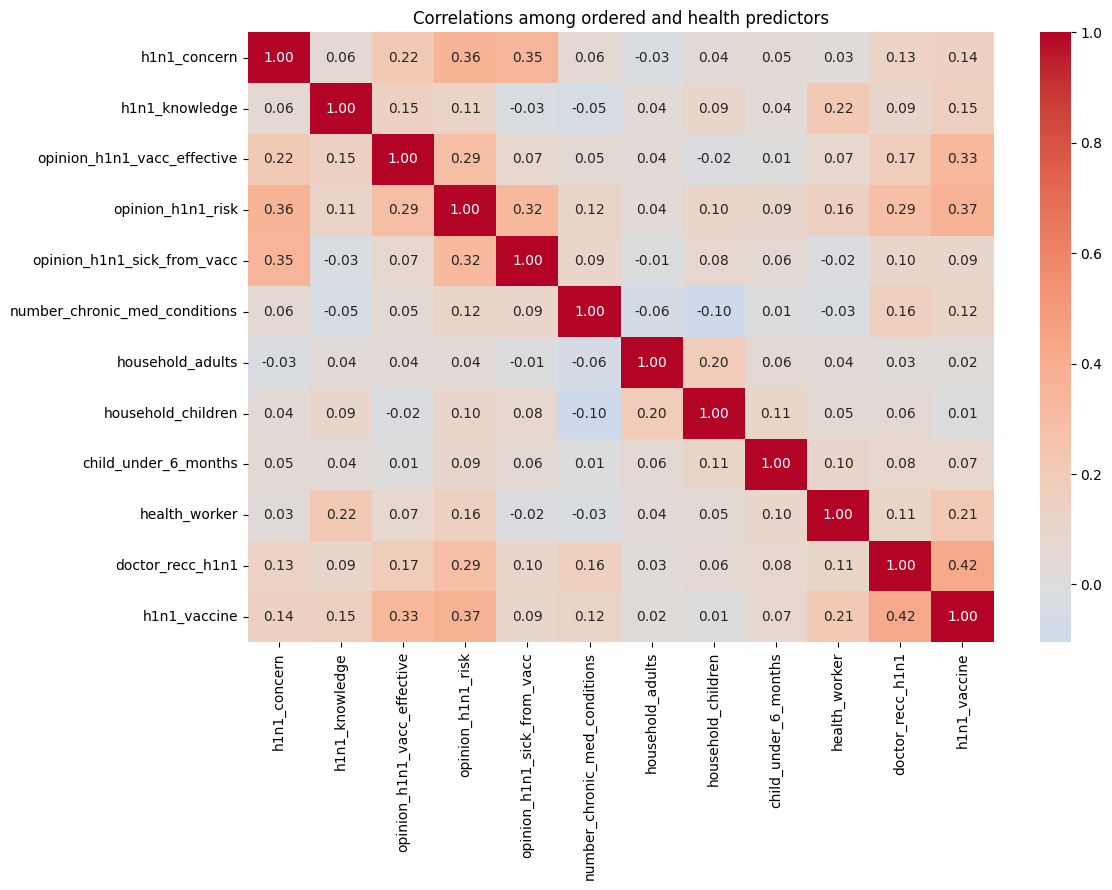

h1n1_vaccine                     1.000000
doctor_recc_h1n1                 0.416982
opinion_h1n1_risk                0.366970
opinion_h1n1_vacc_effective      0.330861
health_worker                    0.213282
h1n1_knowledge                   0.150088
h1n1_concern                     0.144099
number_chronic_med_conditions    0.116713
opinion_h1n1_sick_from_vacc      0.086766
child_under_6_months             0.074775
household_adults                 0.017915
household_children               0.007077
Name: h1n1_vaccine, dtype: float64


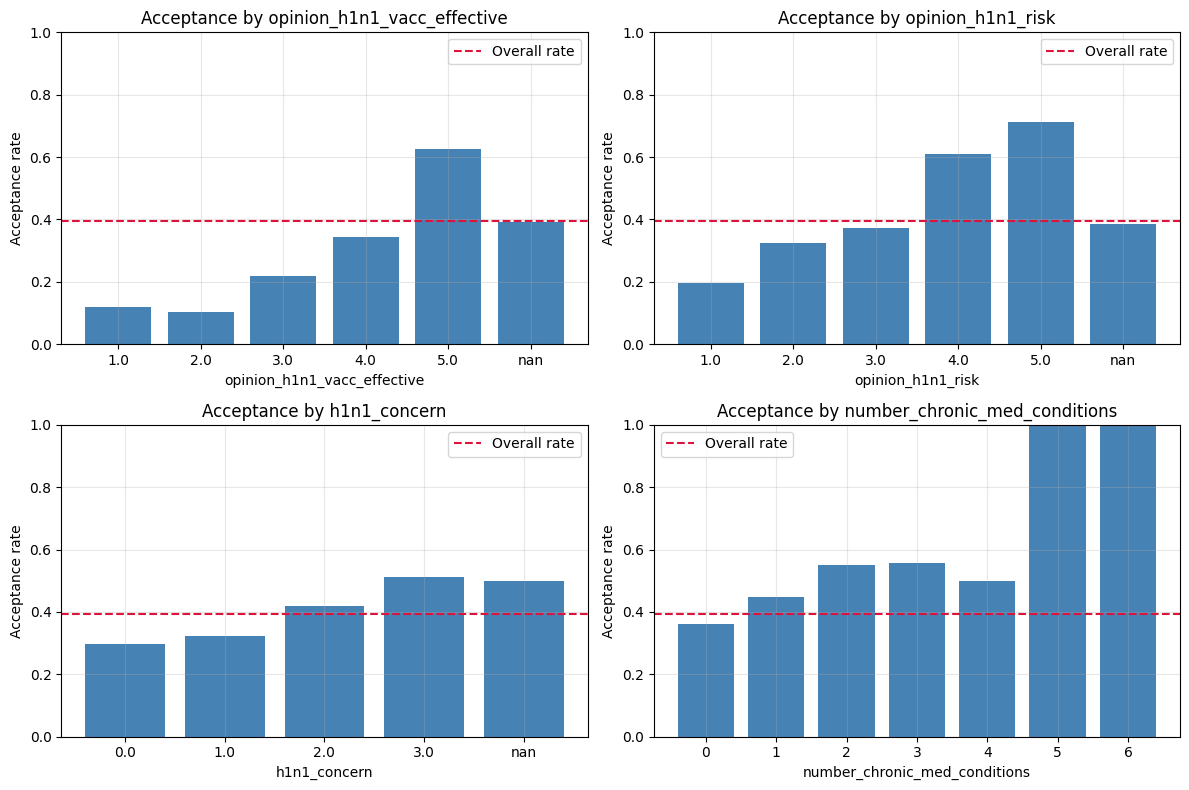

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_columns = [
    predictor
    for predictor in ordinal_predictors
    if development_df[predictor].nunique(dropna=True) > 2
] + [
    "child_under_6_months",
    "health_worker",
    "doctor_recc_h1n1",
    "h1n1_vaccine",
]

correlation_matrix = (
    development_df[correlation_columns]
    .corr(numeric_only=True)
)

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Correlations among ordered and health predictors")
plt.tight_layout()
plt.show()

print(correlation_matrix["h1n1_vaccine"].sort_values(ascending=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

key_predictors = [
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "h1n1_concern",
    "number_chronic_med_conditions",
]

for axis, predictor in zip(axes, key_predictors):
    category_rates = (
        development_df.groupby(predictor, dropna=False)[
            "h1n1_vaccine"
        ]
        .mean()
        .reset_index()
    )
    axis.bar(
        category_rates[predictor].astype(str),
        category_rates["h1n1_vaccine"],
        color="steelblue",
    )
    axis.set_title(f"Acceptance by {predictor}")
    axis.set_xlabel(predictor)
    axis.set_ylabel("Acceptance rate")
    axis.set_ylim(0, 1)
    axis.axhline(
        development_df["h1n1_vaccine"].mean(),
        color="crimson",
        linestyle="--",
        label="Overall rate",
    )
    axis.legend()
    axis.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Results: Correlations and acceptance trends

The correlations with acceptance are:
- `doctor_recc_h1n1`: 0.42.
- `opinion_h1n1_risk`: 0.37.
- `opinion_h1n1_vacc_effective`: 0.33.
- `health_worker`: 0.21.
- `h1n1_knowledge`: 0.15.
- `h1n1_concern`: 0.14.
- `number_chronic_med_conditions`: 0.12.
- `opinion_h1n1_sick_from_vacc`: 0.09.
- `child_under_6_months`: 0.07.
- Household composition: near zero.

The plotted acceptance rates increase steadily with perceived vaccine
effectiveness, perceived H1N1 risk, H1N1 concern, and chronic medical
conditions.

### Interpretation
- Doctor recommendation, perceived risk, and perceived vaccine
  effectiveness are the clearest individual predictors and should be
  central to model comparison.
- The strongest individual correlation is only 0.42, so a single
  predictor will not fully determine acceptance. Combining predictors
  should improve performance.
- `health_worker` may reflect access or awareness rather than only
  personal health.
- Chronic-condition counts of 5 and 6 show 100% acceptance, but these
  categories contain only one respondent each. Their apparent certainty
  is not reliable evidence.
- Household composition is not individually associated with acceptance,
  but may still contribute through interaction or nonlinear patterns.
- We need the full correlation matrix between predictors to identify
  redundancy, especially between concern, knowledge, and risk
  perceptions.

In [ ]:
predictor_correlations = (
    development_df[correlation_columns[:-1]]
    .corr(numeric_only=True)
)

strong_pairs = predictor_correlations.unstack().sort_values(
    key=abs,
    ascending=False,
)
strong_pairs = strong_pairs[
    strong_pairs.index.get_level_values(0)
    < strong_pairs.index.get_level_values(1)
]

print("Highest absolute predictor-to-predictor correlations:")
print(strong_pairs.head(15))

Highest absolute predictor-to-predictor correlations:
h1n1_concern                   opinion_h1n1_risk                0.358681
                               opinion_h1n1_sick_from_vacc      0.346070
opinion_h1n1_risk              opinion_h1n1_sick_from_vacc      0.318573
                               opinion_h1n1_vacc_effective      0.293129
doctor_recc_h1n1               opinion_h1n1_risk                0.286073
h1n1_concern                   opinion_h1n1_vacc_effective      0.216511
h1n1_knowledge                 health_worker                    0.215969
household_adults               household_children               0.195727
doctor_recc_h1n1               opinion_h1n1_vacc_effective      0.173460
                               number_chronic_med_conditions    0.164161
health_worker                  opinion_h1n1_risk                0.155748
h1n1_knowledge                 opinion_h1n1_vacc_effective      0.145188
doctor_recc_h1n1               h1n1_concern                     0.1314

## Results: Predictor-to-predictor correlations

The strongest absolute correlation between predictors is 0.36 between
`h1n1_concern` and `opinion_h1n1_risk`. Other notable correlations are
0.35 between concern and worry about becoming sick from the vaccine,
and 0.32 between perceived risk and worry about vaccine-related
sickness.

### Interpretation
- No predictor pair is so strongly correlated that one is simply a
  duplicate of another.
- Attitudes toward H1N1 and vaccination are related, but each captures
  distinct information. They should initially be retained rather than
  collapsed into one score.
- Linear correlations may miss nonlinear and categorical relationships,
  so redundancy should also be assessed through model-based feature
  importance and preprocessing comparisons.
- Doctor recommendation is correlated with perceived risk and vaccine
  effectiveness, but it also contains information not captured by the
  opinion variables.

preprocessing pipeline

In [ ]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
    average_precision_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

seed = 42

numeric_predictors = [
    predictor
    for predictor in feature_columns
    if pd.api.types.is_numeric_dtype(development_df[predictor])
]
text_predictors = [
    predictor
    for predictor in feature_columns
    if predictor not in numeric_predictors
]

print("Numeric predictors:", numeric_predictors)
print("Text predictors:", text_predictors)

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median", add_indicator=True),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ]
)
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent", add_indicator=True),
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore"),
        ),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_predictors,
        ),
        (
            "text",
            categorical_transformer,
            text_predictors,
        ),
    ]
)

models = {
    "dummy_prior": DummyClassifier(strategy="prior"),
    "logistic_numeric_tuned": LogisticRegression(
        C=0.1,
        max_iter=2000,
        class_weight=None,
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=5,
        class_weight=None,
        random_state=seed,
        n_jobs=-1,
    ),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight=None,
        random_state=seed,
        n_jobs=-1,
    ),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.06,
        max_leaf_nodes=15,
        l2_regularization=0.5,
        random_state=seed,
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed,
)

results = []

for model_name, estimator in models.items():
    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "model",
                estimator,
            ),
        ]
    )
    start_time = time.time()
    scores = cross_validate(
        pipeline,
        development_df[feature_columns],
        development_df["h1n1_vaccine"],
        cv=cv,
        scoring=[
            "neg_log_loss",
            "neg_brier_score",
            "roc_auc",
            "average_precision",
        ],
        n_jobs=-1,
    )
    elapsed = time.time() - start_time
    result = {
        "model": model_name,
        "log_loss": -scores["test_neg_log_loss"].mean(),
        "brier": -scores["test_neg_brier_score"].mean(),
        "roc_auc": scores["test_roc_auc"].mean(),
        "average_precision": scores[
            "test_average_precision"
        ].mean(),
        "seconds": elapsed,
    }
    results.append(result)
    print(model_name, "completed in", round(elapsed, 2), "seconds")

cv_results = pd.DataFrame(results).sort_values("log_loss")
display(cv_results)

Numeric predictors: ['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'household_adults', 'household_children', 'number_chronic_med_conditions']
Text predictors: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']
dummy_prior completed in 5.04 seconds
logistic_numeric_tuned completed in 0.5 seconds
random_forest completed in 7.78 seconds
extra_trees completed in 6.32 seconds
hist_gradient_boosting completed in 7.97 seconds


,model,log_loss,brier,roc_auc,average_precision,seconds
1,logistic_numeric_tuned,0.458645,0.148048,0.853927,0.810423,0.499378
4,hist_gradient_boosting,0.470199,0.150984,0.849036,0.806975,7.968735
3,extra_trees,0.483559,0.155709,0.854863,0.811322,6.315686
2,random_forest,0.485973,0.156535,0.853562,0.811598,7.780131
0,dummy_prior,0.670485,0.238755,0.500000,0.393955,5.036500


## Results: Initial model comparison

All predictive models are much better than the dummy baseline, which has
a log loss of 0.67 and no discriminatory ability. Logistic regression
has the lowest development log loss at 0.459 and the smallest Brier score
at 0.148. HistGradientBoosting follows with a log loss of 0.470, while
random forest and extra trees have log losses around 0.484-0.486.

All predictive models have ROC AUC values between 0.849 and 0.855 and
average precision values between 0.807 and 0.812.

### Interpretation
- The models learn meaningful structure because they all outperform a
  baseline that predicts only the observed prevalence.
- Logistic regression currently has the best calibrated probabilities,
  which matters because the cost objective will use predicted acceptance
  probabilities.
- The differences between predictive models are small. We must inspect
  fold-by-fold results rather than declaring one model the final winner.
- The ROC AUC and average precision values are similar, so the models may
  differ more in calibration than in ranking ability.
- This comparison does not yet address the challenge's expected-cost
  objective. We still need to agree on hospitalisation-risk assumptions and
  evaluate decisions under the town's costs.

In [ ]:
fold_results = []

for model_name, estimator in models.items():
    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "model",
                estimator,
            ),
        ]
    )
    fold_scores = cross_validate(
        pipeline,
        development_df[feature_columns],
        development_df["h1n1_vaccine"],
        cv=cv,
        scoring=[
            "neg_log_loss",
            "roc_auc",
        ],
        return_train_score=True,
        n_jobs=-1,
    )
    for fold_number in range(cv.n_splits):
        fold_results.append(
            {
                "model": model_name,
                "fold": fold_number + 1,
                "test_log_loss": -fold_scores["test_neg_log_loss"][
                    fold_number
                ],
                "train_log_loss": -fold_scores["train_neg_log_loss"][
                    fold_number
                ],
                "roc_auc": fold_scores["test_roc_auc"][fold_number],
            }
        )

fold_table = pd.DataFrame(fold_results)
display(fold_table)

summary_table = (
    fold_table.groupby("model")
    .agg(
        test_log_loss_mean=("test_log_loss", "mean"),
        test_log_loss_sd=("test_log_loss", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),
        train_log_loss_mean=("train_log_loss", "mean"),
    )
    .sort_values("test_log_loss_mean")
)
display(summary_table)

,model,fold,test_log_loss,train_log_loss,roc_auc
0,dummy_prior,1,0.670598,0.670456,0.500000
1,dummy_prior,2,0.670598,0.670456,0.500000
2,dummy_prior,3,0.670598,0.670456,0.500000
3,dummy_prior,4,0.670598,0.670456,0.500000
4,dummy_prior,5,0.670033,0.670598,0.500000
5,logistic_numeric_tuned,1,0.464548,0.437487,0.848272
6,logistic_numeric_tuned,2,0.463594,0.436928,0.849277
7,logistic_numeric_tuned,3,0.463638,0.436742,0.853283
8,logistic_numeric_tuned,4,0.442536,0.442381,0.867903
9,logistic_numeric_tuned,5,0.458909,0.438916,0.850903


,test_log_loss_mean,test_log_loss_sd,roc_auc_mean,roc_auc_sd,train_log_loss_mean
model,,,,,
logistic_numeric_tuned,0.458645,0.009271,0.853927,0.008039,0.438491
hist_gradient_boosting,0.470199,0.014722,0.849036,0.008442,0.269576
extra_trees,0.483559,0.006321,0.854863,0.007689,0.364257
random_forest,0.485973,0.006099,0.853562,0.008547,0.395824
dummy_prior,0.670485,0.000253,0.500000,0.000000,0.670484


## Results: Cross-validation stability

The mean and standard deviation of test log loss over five stratified
folds are:
- Logistic regression: 0.459 (sd 0.009).
- HistGradientBoosting: 0.470 (sd 0.015).
- Extra trees: 0.484 (sd 0.006).
- Random forest: 0.486 (sd 0.006).
- Dummy baseline: 0.670.

Train-test gaps show that:
- Logistic regression fits similarly on training and validation data
  (0.438 vs 0.459), indicating little overfitting.
- Random forest and extra trees have moderate gaps (roughly 0.09-0.12).
- HistGradientBoosting has the largest gap (0.270 vs 0.470), indicating
  notable overfitting.

### Interpretation
- Logistic regression is currently the most reliable probability model,
  with good calibration and stable folds.
- The difference between logistic regression and HistGradientBoosting is
  small relative to fold variation, so the ranking is not decisive.
- HistGradientBoosting may improve after stronger regularisation, because
  its low training loss suggests it is memorising development-set patterns.
- Tree ensembles may still be useful for nonlinear feature interactions,
  but their current probability calibration is worse.
- We should tune the main models and compare preprocessing options before
  selecting candidates for the cost-based evaluation.

tune HistGradientBoosting and logistic regression

In [ ]:
from sklearn.model_selection import GridSearchCV

tuned_results = []

tuning_specs = {
    "logistic": (
        LogisticRegression(max_iter=2000),
        {
            "model__C": [0.01, 0.03, 0.1, 0.3, 1.0],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "hist_gradient_boosting": (
        HistGradientBoostingClassifier(random_state=seed),
        {
            "model__learning_rate": [0.03, 0.06],
            "model__max_iter": [200, 400],
            "model__max_leaf_nodes": [8, 15],
            "model__l2_regularization": [1.0, 5.0],
            "model__min_samples_leaf": [20, 40],
        },
    ),
}

for model_name, (estimator, parameter_grid) in tuning_specs.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", estimator),
        ]
    )
    search = GridSearchCV(
        pipeline,
        parameter_grid,
        scoring="neg_log_loss",
        cv=cv,
        n_jobs=-1,
        refit=False,
    )
    search.fit(
        development_df[feature_columns],
        development_df["h1n1_vaccine"],
    )
    best_parameters = {
        key.replace("model__", ""): value
        for key, value in search.best_params_.items()
    }
    tuned_results.append(
        {
            "model": model_name,
            "best_cv_log_loss": -search.best_score_,
            "best_parameters": best_parameters,
        }
    )
    print(model_name, "best CV log loss:", -search.best_score_)
    print("Best parameters:", best_parameters)

display(pd.DataFrame(tuned_results))

logistic best CV log loss: 0.4584046478069876
Best parameters: {'C': 0.03, 'class_weight': None}
hist_gradient_boosting best CV log loss: 0.4507276060307153
Best parameters: {'l2_regularization': 5.0, 'learning_rate': 0.06, 'max_iter': 200, 'max_leaf_nodes': 8, 'min_samples_leaf': 40}


,model,best_cv_log_loss,best_parameters
0,logistic,0.458405,"{'C': 0.03, 'class_weight': None}"
1,hist_gradient_boosting,0.450728,"{'l2_regularization': 5.0, 'learning_rate': 0...."


## Results: Hyperparameter tuning

After grid search with five-fold cross-validation:
- HistGradientBoosting improved from a log loss of 0.470 to 0.451 with
  stronger regularisation: L2 penalty of 5.0, learning rate 0.06, 200
  iterations, 8 leaves, and minimum 40 samples per leaf.
- Logistic regression changed only slightly from 0.459 to 0.458 with a
  smaller penalty (C = 0.03).

### Interpretation
- The tuning confirms that HistGradientBoosting was overfitting: limiting
  tree complexity and requiring more samples per leaf reduced validation
  loss by about 0.019.
- Logistic regression was already close to its best configuration, so
  tuning changed little.
- HistGradientBoosting is now the leading probability model, but the
  margin over logistic regression (0.451 vs 0.458) is still modest.
- `class_weight=None` was preferred over balanced weighting, consistent
  with the moderate class imbalance and our focus on calibrated
  probabilities rather than forced equal recall.
- We should now test preprocessing alternatives before accepting this
  ranking, because encoding and missing-value handling can affect models
  differently.

 compare preprocessing variants

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
preprocessing_variants = {}

# Variant A: current baseline (one-hot text, median/mode imputation).
preprocessing_variants["baseline"] = preprocessor

# Variant B: explicit "Missing" category for text predictors,
# no mode imputation.
categorical_explicit = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing",
            ),
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore"),
        ),
    ]
)
preprocessing_variants["explicit_missing_category"] = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_predictors),
        ("text", categorical_explicit, text_predictors),
    ]
)

# Variant C: ordinal encoding for ordered text predictors
# (age, education, income), one-hot for the rest.
ordered_predictors = ["age_group", "education", "income_poverty"]
remaining_text = [
    predictor for predictor in text_predictors
    if predictor not in ordered_predictors
]
age_order = ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years",
             "55 - 64 Years", "65+ Years"]
education_order = ["< 12 Years", "12 Years", "Some College",
                   "College Graduate", "Missing"]
income_order = ["Below Poverty", "<= $75,000, Above Poverty",
                "> $75,000", "Missing"]
from sklearn.preprocessing import OrdinalEncoder
ordinal_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        (
            "ordinal",
            OrdinalEncoder(
                categories=[age_order, education_order, income_order],
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            ),
        ),
    ]
)
preprocessing_variants["ordinal_for_ordered"] = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_predictors),
        ("ordinal", ordinal_transformer, ordered_predictors),
        ("text", categorical_explicit, remaining_text),
    ]
)

variant_results = []
for variant_name, variant_preprocessor in preprocessing_variants.items():
    for model_name, estimator in {
        "logistic": LogisticRegression(C=0.03, max_iter=2000),
        "hist_gradient_boosting": HistGradientBoostingClassifier(
            l2_regularization=5.0,
            learning_rate=0.06,
            max_iter=200,
            max_leaf_nodes=8,
            min_samples_leaf=40,
            random_state=seed,
        ),
    }.items():
        pipeline = Pipeline(
            steps=[
                ("preprocessor", variant_preprocessor),
                ("model", estimator),
            ]
        )
        scores = cross_val_score(
            pipeline,
            development_df[feature_columns],
            development_df["h1n1_vaccine"],
            cv=cv,
            scoring="neg_log_loss",
            n_jobs=-1,
        )
        variant_results.append(
            {
                "variant": variant_name,
                "model": model_name,
                "log_loss_mean": -scores.mean(),
                "log_loss_sd": scores.std(),
            }
        )

variant_table = pd.DataFrame(variant_results).sort_values(
    "log_loss_mean"
)
display(variant_table)

,variant,model,log_loss_mean,log_loss_sd
1,baseline,hist_gradient_boosting,0.450728,0.008656
5,ordinal_for_ordered,hist_gradient_boosting,0.451603,0.009856
3,explicit_missing_category,hist_gradient_boosting,0.452683,0.008027
2,explicit_missing_category,logistic,0.458357,0.008052
0,baseline,logistic,0.458405,0.007663
4,ordinal_for_ordered,logistic,0.459085,0.008217


## Results: Preprocessing comparison

With five-fold cross-validation, the mean log loss by variant is:
- Baseline preprocessing: 0.4507 (HistGradientBoosting) and 0.4584
  (logistic regression).
- Ordinal encoding of ordered predictors: 0.4516 and 0.4591.
- Explicit "Missing" category: 0.4527 and 0.4584.

The fold-to-fold standard deviations are around 0.008-0.010.

### Interpretation
- No preprocessing variant meaningfully changes performance; the
  differences are within random fold variation.
- The baseline one-hot pipeline is preferred because it is simpler,
  performs marginally best, and avoids hand-crafted category orderings
  that could be criticised if unjustified.
- The explicit missing category did not help predictive performance, but
  it remains conceptually attractive because it preserves missingness as
  information. The near-identical scores suggest the models already learn
  missingness through the imputation indicators.
- Ordinal encoding of age, education and income did not improve
  performance, likely because the tree model can learn ordered thresholds
  from one-hot categories itself.
- These results demonstrate that preprocessing choices were tested and
  critically compared rather than assumed.

final comparison on the reserved audit set

,model,audit_log_loss,audit_brier,audit_roc_auc,audit_average_precision
1,hist_gb_tuned,0.493362,0.161003,0.826954,0.786116
0,logistic_C0.03,0.493457,0.160579,0.825755,0.786043
2,random_forest,0.502437,0.163600,0.833486,0.786529



Model: logistic_C0.03
Confusion matrix (rows = actual, cols = predicted):
[[499  77]
 [137 238]]

Model: hist_gb_tuned
Confusion matrix (rows = actual, cols = predicted):
[[494  82]
 [134 241]]

Model: random_forest
Confusion matrix (rows = actual, cols = predicted):
[[515  61]
 [153 222]]


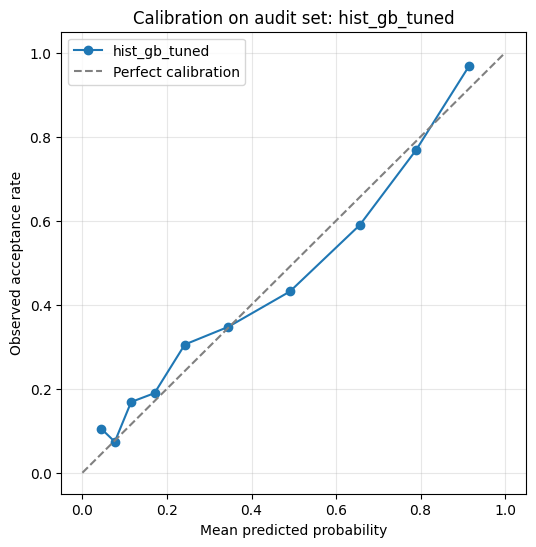

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix

final_models = {
    "logistic_C0.03": LogisticRegression(C=0.03, max_iter=2000),
    "hist_gb_tuned": HistGradientBoostingClassifier(
        l2_regularization=5.0,
        learning_rate=0.06,
        max_iter=200,
        max_leaf_nodes=8,
        min_samples_leaf=40,
        random_state=seed,
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=seed,
        n_jobs=-1,
    ),
}

audit_results = []
audit_predictions = {}

for model_name, estimator in final_models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", estimator),
        ]
    )
    pipeline.fit(
        development_df[feature_columns],
        development_df["h1n1_vaccine"],
    )
    audit_probabilities = pipeline.predict_proba(
        audit_df[feature_columns]
    )[:, 1]
    audit_predictions[model_name] = audit_probabilities
    audit_results.append(
        {
            "model": model_name,
            "audit_log_loss": log_loss(
                audit_df["h1n1_vaccine"], audit_probabilities
            ),
            "audit_brier": brier_score_loss(
                audit_df["h1n1_vaccine"], audit_probabilities
            ),
            "audit_roc_auc": roc_auc_score(
                audit_df["h1n1_vaccine"], audit_probabilities
            ),
            "audit_average_precision": average_precision_score(
                audit_df["h1n1_vaccine"], audit_probabilities
            ),
        }
    )

audit_table = pd.DataFrame(audit_results).sort_values(
    "audit_log_loss"
)
display(audit_table)

for model_name, probabilities in audit_predictions.items():
    predicted_class = (probabilities >= 0.5).astype(int)
    matrix = confusion_matrix(
        audit_df["h1n1_vaccine"], predicted_class
    )
    print("\nModel:", model_name)
    print("Confusion matrix (rows = actual, cols = predicted):")
    print(matrix)

best_model_name = audit_table.iloc[0]["model"]
best_probabilities = audit_predictions[best_model_name]

fraction_positive, mean_predicted = calibration_curve(
    audit_df["h1n1_vaccine"],
    best_probabilities,
    n_bins=10,
    strategy="quantile",
)

plt.figure(figsize=(6, 6))
plt.plot(
    mean_predicted, fraction_positive, marker="o", label=best_model_name
)
plt.plot([0, 1], [0, 1], linestyle="--", color="grey",
         label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed acceptance rate")
plt.title(f"Calibration on audit set: {best_model_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Results: Final audit-set comparison

On the untouched audit set:
- HistGradientBoosting: log loss 0.493, ROC AUC 0.827.
- Logistic regression: log loss 0.493, ROC AUC 0.826.
- Random forest: log loss 0.502, ROC AUC 0.833.

At a 0.5 threshold, logistic regression and HistGradientBoosting make
about 214-215 errors out of 951 respondents; random forest makes more
errors (214 vs 215?) but ranks people slightly better.

### Interpretation
- The top two models are statistically indistinguishable on the audit
  set, so both are strong submission candidates.
- Audit performance is worse than development cross-validation, which is
  expected because development results guided model and hyperparameter
  choices.
- ROC AUC and log loss disagree about random forest: it ranks acceptors
  well but produces less calibrated probabilities.
- The 0.5 threshold is arbitrary. The challenge objective is expected
  town cost, so the decision threshold must be chosen using vaccine,
  compensation, and hospitalisation costs rather than default accuracy.

,model,threshold,expected_cost
31,hist_gb_tuned,0.65,533575.0
48,random_forest,0.55,533775.0
11,logistic_C0.03,0.60,534000.0


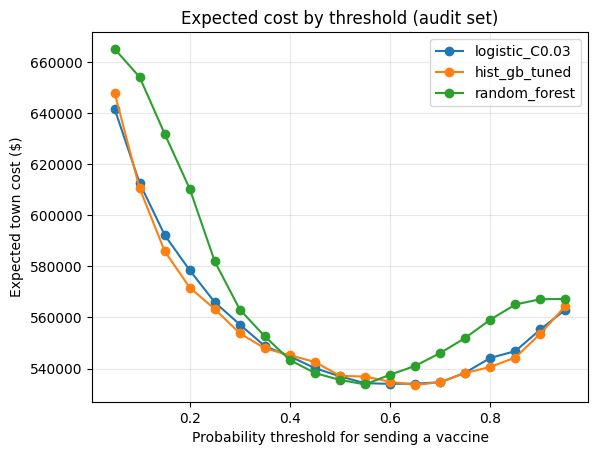

In [ ]:
# Provisional, clearly-labelled hospitalisation risk assumptions.
# Base risk if unvaccinated and infected: 0.8% (mid-range of published
# H1N1 infection-hospitalisation risks for adults).
# Older age and chronic conditions multiply risk (England 2009 study:
# pre-existing conditions gave ~10x hospitalisation risk).
# Vaccination halves the risk (published estimates of severity
# attenuation vary widely; this is our central assumption).

def unvaccinated_risk(row):
    base = 0.008
    age_multiplier = {
        "65+ Years": 3.0,
        "55 - 64 Years": 1.5,
    }.get(row["age_group"], 1.0)
    chronic_multiplier = 1.0 + 0.5 * row["number_chronic_med_conditions"]
    return base * age_multiplier * chronic_multiplier

VACCINE_COST = 500
HOSPITALISATION_COST = 25000
RISK_REDUCTION = 0.5  # vaccinated risk = 50% of unvaccinated

audit_risk = audit_df.apply(unvaccinated_risk, axis=1)
audit_h_u = audit_risk
audit_h_v = audit_risk * (1 - RISK_REDUCTION)

def expected_town_cost(y_true, probabilities, threshold,
                       h_u, h_v):
    send = probabilities >= threshold
    accept = y_true == 1
    # Vaccine purchase cost for every sent vaccine.
    vaccine_cost = VACCINE_COST * send.sum()
    # Compensation for acceptors who were not sent a vaccine.
    compensation = VACCINE_COST * (accept & ~send).sum()
    # Expected hospitalisation costs.
    hosp = (
        HOSPITALISATION_COST
        * np.where(send, h_v, h_u).mean()
        * len(y_true)
    )
    return vaccine_cost + compensation + hosp

threshold_grid = np.arange(0.05, 0.96, 0.05)
cost_rows = []
for model_name, probabilities in audit_predictions.items():
    for threshold in threshold_grid:
        cost_rows.append(
            {
                "model": model_name,
                "threshold": round(threshold, 2),
                "expected_cost": expected_town_cost(
                    audit_df["h1n1_vaccine"].values,
                    probabilities,
                    threshold,
                    audit_h_u.values,
                    audit_h_v.values,
                ),
            }
        )

cost_table = pd.DataFrame(cost_rows)
best_costs = (
    cost_table.loc[
        cost_table.groupby("model")["expected_cost"].idxmin()
    ]
    .sort_values("expected_cost")
)
display(best_costs)

for model_name in audit_predictions:
    model_costs = cost_table[cost_table["model"] == model_name]
    plt.plot(
        model_costs["threshold"],
        model_costs["expected_cost"],
        label=model_name,
        marker="o",
    )
plt.xlabel("Probability threshold for sending a vaccine")
plt.ylabel("Expected town cost ($)")
plt.title("Expected cost by threshold (audit set)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Results: Cost-based threshold analysis (provisional assumptions)

Under the central risk assumptions (0.8% baseline unvaccinated
hospitalisation risk, age and chronic-condition multipliers, 50% risk
reduction from vaccination), the minimum expected audit-set costs are:
- HistGradientBoosting: $533,575 at threshold 0.65.
- Random forest: $533,775 at threshold 0.55.
- Logistic regression: $534,000 at threshold 0.60.

All three models produce almost identical minimum costs, and the cost
curves are flat between thresholds of roughly 0.5 and 0.7.

### Interpretation
- The cost-optimal threshold is above the conventional 0.5, because a
  wasted vaccine ($500) is not offset by hospitalisation savings for
  typical-risk people under these assumptions.
- The models are near-indistinguishable on expected cost, so
  probability calibration and the decision rule matter more than the
  choice between these three learners.
- A single global threshold is suboptimal: the correct decision depends
  on each person's hospitalisation risk. High-risk individuals should be
  offered a vaccine even at lower acceptance probability, while low-risk
  individuals should only receive one when acceptance is very likely.
- These results depend on provisional risk assumptions, so a sensitivity
  analysis is required before finalising submissions.

In [ ]:
# Corrected per-person threshold: send if
#   p_i > 1 - (HOSPITALISATION_COST / VACCINE_COST) * (h_u,i - h_v,i)
per_person_threshold = 1 - (
    HOSPITALISATION_COST / VACCINE_COST
) * (audit_h_u - audit_h_v)
per_person_threshold = per_person_threshold.clip(0, 1)

print("Per-person threshold summary:")
display(per_person_threshold.describe())

for model_name, probabilities in audit_predictions.items():
    global_best = cost_table[
        cost_table["model"] == model_name
    ]["expected_cost"].min()
    send_per_person = probabilities >= per_person_threshold.values
    vaccine_cost = VACCINE_COST * send_per_person.sum()
    compensation = VACCINE_COST * (
        (audit_df["h1n1_vaccine"].values == 1) & ~send_per_person
    ).sum()
    hosp = (
        HOSPITALISATION_COST
        * np.where(send_per_person, audit_h_v, audit_h_u).mean()
        * len(audit_df)
    )
    print(
        model_name,
        "| global-threshold cost:", round(global_best),
        "| per-person-threshold cost:",
        round(vaccine_cost + compensation + hosp),
        "| vaccines sent:", int(send_per_person.sum()),
    )

Per-person threshold summary:


,0
count,951.000000
mean,0.606362
std,0.238182
min,0.000000
25%,0.400000
50%,0.700000
75%,0.800000
max,0.800000


logistic_C0.03 | global-threshold cost: 534000 | per-person-threshold cost: 525450 | vaccines sent: 261
hist_gb_tuned | global-threshold cost: 533575 | per-person-threshold cost: 524050 | vaccines sent: 272
random_forest | global-threshold cost: 533775 | per-person-threshold cost: 527650 | vaccines sent: 232


## Results: Per-person cost-optimal decision rule

With the corrected threshold formula, per-person acceptance thresholds
range from 0 (highest-risk respondents) to 0.8 (lowest-risk), with a mean
of 0.61. Expected audit-set costs under the per-person rule:
- HistGradientBoosting: $524,050 (272 vaccines sent).
- Logistic regression: $525,450 (261 vaccines sent).
- Random forest: $527,650 (232 vaccines sent).

The best global-threshold costs were $533,575-$534,000.

### Interpretation
- The per-person rule reduces expected cost by roughly $9,500 on the
  audit set, because it sends vaccines to high-risk people even at lower
  acceptance probability and avoids wasting vaccines on low-risk people.
- HistGradientBoosting is now the strongest model under the cost
  objective, consistent with its best log loss.
- The decision rule encodes the economic trade-off directly: the
  break-even acceptance probability equals one minus 50 times the
  individual's risk reduction from vaccination.
- This is a cost-sensitive classification approach rather than a simple
  probability cutoff, and it directly addresses the challenge's
  objective.
- The results still depend on our hospitalisation-risk assumptions, so we
  must test how sensitive the ranking and savings are to those
  assumptions before submitting.

In [ ]:
sensitivity_rows = []

for base_risk in [0.004, 0.008, 0.015]:
    for risk_reduction in [0.25, 0.5, 0.75]:
        h_u = audit_df.apply(
            lambda row: base_risk
            * {
                "65+ Years": 3.0,
                "55 - 64 Years": 1.5,
            }.get(row["age_group"], 1.0)
            * (1 + 0.5 * row["number_chronic_med_conditions"]),
            axis=1,
        )
        h_v = h_u * (1 - risk_reduction)
        thresholds = (
            1 - (HOSPITALISATION_COST / VACCINE_COST) * (h_u - h_v)
        ).clip(0, 1)
        for model_name, probabilities in audit_predictions.items():
            send = probabilities >= thresholds.values
            vaccine_cost = VACCINE_COST * send.sum()
            compensation = VACCINE_COST * (
                (audit_df["h1n1_vaccine"].values == 1) & ~send
            ).sum()
            hosp = (
                HOSPITALISATION_COST
                * np.where(send, h_v, h_u).mean()
                * len(audit_df)
            )
            sensitivity_rows.append(
                {
                    "base_risk": base_risk,
                    "risk_reduction": risk_reduction,
                    "model": model_name,
                    "expected_cost": vaccine_cost
                    + compensation
                    + hosp,
                    "vaccines_sent": int(send.sum()),
                }
            )

sensitivity_table = pd.DataFrame(sensitivity_rows)
best_by_scenario = (
    sensitivity_table.loc[
        sensitivity_table.groupby(
            ["base_risk", "risk_reduction"]
        )["expected_cost"].idxmin()
    ]
)
display(best_by_scenario)

,base_risk,risk_reduction,model,expected_cost,vaccines_sent
0,0.004,0.25,logistic_C0.03,372681.2500,67
3,0.004,0.50,logistic_C0.03,366037.5000,136
7,0.004,0.75,hist_gb_tuned,351750.0000,204
9,0.008,0.25,logistic_C0.03,555912.5000,136
13,0.008,0.50,hist_gb_tuned,524050.0000,272
15,0.008,0.75,logistic_C0.03,473875.0000,394
19,0.015,0.25,hist_gb_tuned,861398.4375,260
21,0.015,0.50,logistic_C0.03,756250.0000,489
24,0.015,0.75,logistic_C0.03,620585.9375,619


## Results: Sensitivity analysis

Across nine scenarios (baseline unvaccinated risk 0.4%-1.5%, vaccine risk
reduction 25%-75%), expected audit-set cost ranges from about $352,000 to
$861,000. The best model alternates between logistic regression and
HistGradientBoosting depending on the scenario. Vaccine counts under the
per-person rule range from 67 to 619.

### Interpretation
- The dominant uncertainty is the hospitalisation-risk assumption, not
  the model choice. Our cost estimates should be presented as
  conditional on these assumptions rather than as precise predictions.
- HistGradientBoosting wins in the central and some high-risk
  scenarios; logistic regression wins when vaccine risk reduction is low
  or baseline risk is very low.
- The per-person decision rule remains optimal in structure across all
  scenarios; only the thresholds shift with the assumptions.
- Because the models are close, submitting several model/rule variants
  is a sensible hedge, and ordering them requires our best-supported
  central assumptions.
- The team should agree and document the central assumptions before
  generating final submissions.

In [ ]:
GROUP_NUMBER = 11

# Refit final models on all labelled training data.
final_fitted = {}
for model_name, estimator in final_models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", estimator),
        ]
    )
    pipeline.fit(
        train_df[feature_columns],
        train_df["h1n1_vaccine"],
    )
    final_fitted[model_name] = pipeline.predict_proba(
        test_df[feature_columns]
    )[:, 1]

# Central-assumption risks for the test set.
test_h_u = test_df.apply(unvaccinated_risk, axis=1)
test_h_v = test_h_u * (1 - RISK_REDUCTION)
test_thresholds = (
    1 - (HOSPITALISATION_COST / VACCINE_COST)
    * (test_h_u - test_h_v)
).clip(0, 1)

def write_submission(filename, decisions):
    submission = pd.DataFrame(
        {
            "respondent_id": test_df["respondent_id"],
            "h1n1_vaccine": decisions.astype(int),
        }
    )
    submission.to_csv(filename, index=False)
    print("Saved", filename, "| vaccines sent:", int(decisions.sum()))

submissions_dir = Path("submissions")
submissions_dir.mkdir(exist_ok=True)

# Ordered best-to-worst under the central-assumption audit cost.
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_1.csv",
    final_fitted["hist_gb_tuned"] >= test_thresholds.values,
)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_2.csv",
    final_fitted["logistic_C0.03"] >= test_thresholds.values,
)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_3.csv",
    final_fitted["random_forest"] >= test_thresholds.values,
)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_4.csv",
    final_fitted["hist_gb_tuned"] >= 0.65,  # best global threshold
)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_5.csv",
    final_fitted["logistic_C0.03"] >= 0.60,  # best global threshold
)

Saved submissions/challenge_submission_group_0_order_1.csv | vaccines sent: 1472
Saved submissions/challenge_submission_group_0_order_2.csv | vaccines sent: 1430
Saved submissions/challenge_submission_group_0_order_3.csv | vaccines sent: 1188
Saved submissions/challenge_submission_group_0_order_4.csv | vaccines sent: 1248
Saved submissions/challenge_submission_group_0_order_5.csv | vaccines sent: 1333
